In [1]:
from pathlib import Path

In [2]:
import nglview as nv
from pypdb.clients.pdb.pdb_client import get_pdb_file

nv.demo()

NGLWidget()

In [5]:
print("NGLView version:", nv.__version__)
for attr in dir(nv):
    if attr.startswith("show_"):
        print(f"  nv.{attr}(...)")

NGLView version: 4.0.1
  nv.show_ase(...)
  nv.show_asetraj(...)
  nv.show_biopython(...)
  nv.show_file(...)
  nv.show_htmd(...)
  nv.show_iodata(...)
  nv.show_iotbx(...)
  nv.show_mdanalysis(...)
  nv.show_mdtraj(...)
  nv.show_openbabel(...)
  nv.show_parmed(...)
  nv.show_pdbid(...)
  nv.show_prody(...)
  nv.show_psi4(...)
  nv.show_pymatgen(...)
  nv.show_pytraj(...)
  nv.show_qcelemental(...)
  nv.show_rdkit(...)
  nv.show_rosetta(...)
  nv.show_schrodinger(...)
  nv.show_simpletraj(...)
  nv.show_structure_file(...)
  nv.show_text(...)
  nv.show_url(...)


In [6]:
def get_structure(pdb_id):
    # download the PDB file content.
    pdb_file_content = get_pdb_file(pdb_id)
    # create an nglview structure object from the content
    structure = nv.TextStructure(pdb_file_content, ext="pdb")
    return structure


def get_pdb_nglviewer(pdb_id, default_representation=True, gui=False):
    structure = get_structure(pdb_id)
    # set structure viewer
    nglviewer = nv.show_file(structure, default_representation=default_representation, gui=gui)
    return nglviewer

In [8]:
get_structure("3pk2")

Sending GET request to https://files.rcsb.org/download/3pk2.pdb to fetch 3pk2's pdb file as a string.


In [7]:
# nv.show_pdbid("3pk2")
get_pdb_nglviewer("3pk2")

Sending GET request to https://files.rcsb.org/download/3pk2.pdb to fetch 3pk2's pdb file as a string.


NGLWidget()

In [13]:
import urllib.request
import biotite.structure.io as bsio
import biotite.structure as struc

# 1. Download the PDB file directly using standard Python libraries
url = "https://files.rcsb.org/download/1ARM.pdb"
urllib.request.urlretrieve(url, "1ARM.pdb")
print("Downloaded 1ARM.pdb successfully!")

# 2. Load it using Biotite
source_array = bsio.load_structure("1ARM.pdb", extra_fields=["charge"])

# 3. Verification
print(f"Successfully loaded structure! Total atoms: {len(source_array)}")

Downloaded 1ARM.pdb successfully!
Successfully loaded structure! Total atoms: 2666


In [14]:
with open("1ARM.pdb") as f:
    view = nv.show_file(f, ext="pdb")
view

NGLWidget()

In [15]:
view.render_image(trim=True, factor=2)

Image(value=b'', width='99%')

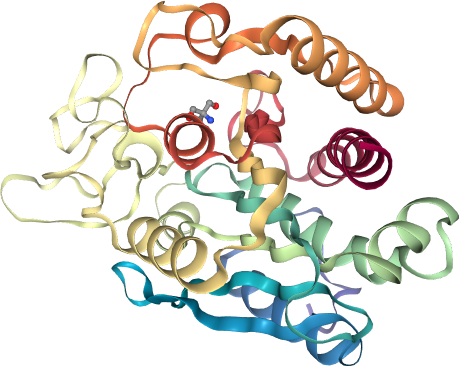

In [16]:
view._display_image()

In [17]:
for attr in dir(view):
    if attr.startswith("add_"):
        print(f"view.{attr}(...)")

view.add_axes(...)
view.add_backbone(...)
view.add_ball_and_stick(...)
view.add_cartoon(...)
view.add_class(...)
view.add_component(...)
view.add_contact(...)
view.add_distance(...)
view.add_helixorient(...)
view.add_hyperball(...)
view.add_label(...)
view.add_licorice(...)
view.add_line(...)
view.add_pdbid(...)
view.add_point(...)
view.add_principal_axes(...)
view.add_representation(...)
view.add_ribbon(...)
view.add_rocket(...)
view.add_rope(...)
view.add_simplified_base(...)
view.add_slice(...)
view.add_spacefill(...)
view.add_structure(...)
view.add_surface(...)
view.add_trace(...)
view.add_traits(...)
view.add_trajectory(...)
view.add_tube(...)
view.add_unitcell(...)


In [18]:
# view = nv.show_pdbid("3pk2", default_representation=False)
view = get_pdb_nglviewer("3pk2", default_representation=False)
view

Sending GET request to https://files.rcsb.org/download/3pk2.pdb to fetch 3pk2's pdb file as a string.


NGLWidget()

In [19]:
# add ribbon to protein only
view.add_cartoon("protein")
view

NGLWidget(n_components=1)

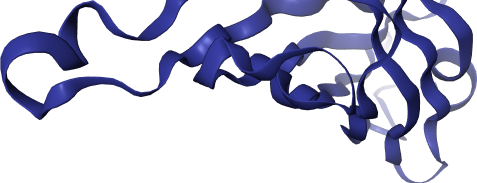

In [21]:
view.render_image(trim=True, factor=2);
view._display_image()

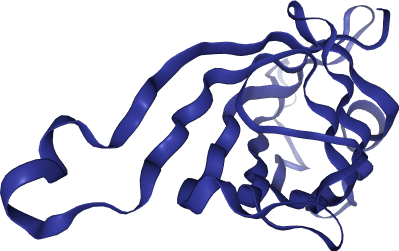

In [23]:
view.center()
view.render_image(trim=True, factor=2);
view._display_image()

In [ ]:
view.add_ball_and_stick("ligand")
view.render_image(trim=True, factor=2);

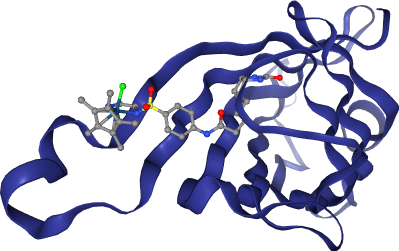

In [26]:
view._display_image()

In [27]:
view.add_line("water")
view.render_image(trim=True, factor=2);

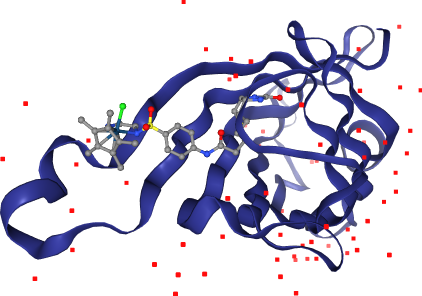

In [28]:
view._display_image()

In [29]:
view.add_spacefill("_Ir")
view.render_image(trim=True, factor=2);

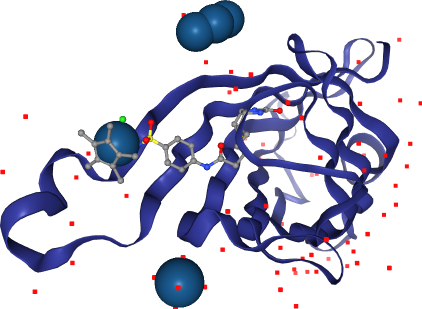

In [30]:
view._display_image()

In [31]:
view.remove_spacefill()
view.render_image(trim=True, factor=2);

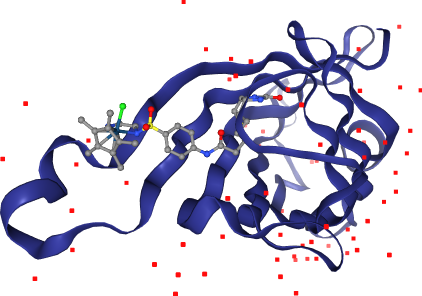

In [32]:
view._display_image()

In [33]:
view.add_spacefill("ligand and _Ir")
view.render_image(trim=True, factor=2);

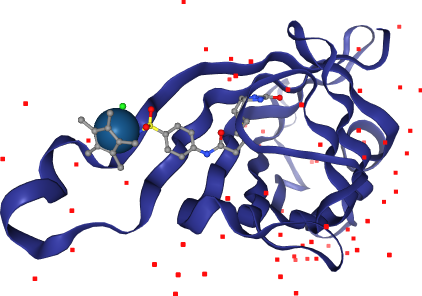

In [34]:
view._display_image()

In [35]:
# By default, first model only
# nv.show_pdbid("1rfo")
get_pdb_nglviewer("1rfo")

Sending GET request to https://files.rcsb.org/download/1rfo.pdb to fetch 1rfo's pdb file as a string.


NGLWidget()

In [38]:
# all models require custom representation
view = get_pdb_nglviewer("1rfo", default_representation=False)
view.center()
view.add_cartoon()
view

Sending GET request to https://files.rcsb.org/download/1rfo.pdb to fetch 1rfo's pdb file as a string.


NGLWidget()

In [39]:
view = get_pdb_nglviewer("1YME")
view

Sending GET request to https://files.rcsb.org/download/1YME.pdb to fetch 1YME's pdb file as a string.


NGLWidget()

In [40]:
# view.add_component(nv.PdbIdStructure("1ARM"))

view.add_component(get_structure("1ARM"))

Sending GET request to https://files.rcsb.org/download/1ARM.pdb to fetch 1ARM's pdb file as a string.


In [41]:
view.n_components

2

In [42]:
view[0]

In [43]:
view.component_0

In [44]:
view[1].hide()

In [45]:
view[1].show()

In [46]:
print(nv.color.COLOR_SCHEMES)

[' ', 'picking', 'random', 'uniform', 'atomindex', 'residueindex', 'chainindex', 'modelindex', 'sstruc', 'element', 'resname', 'bfactor', 'hydrophobicity', 'value', 'volume', 'occupancy']


In [47]:
view = get_pdb_nglviewer("1PIE", default_representation=False)
view.add_ribbon("protein", color_scheme="sstruc")  # color based on secondary structure
view.add_ball_and_stick("ligand")
view.center()
view

Sending GET request to https://files.rcsb.org/download/1PIE.pdb to fetch 1PIE's pdb file as a string.


NGLWidget()

In [48]:
view.add_licorice(
    "sidechainAttached ", color="red"
)  # color="#FF0000" or color=0xFF0000 would also work!

In [49]:
# residues from 1 to 100 will be blue; 101 to 1000 will be red
nv.color.ColormakerRegistry.add_selection_scheme(
    "my_custom_scheme", [["blue", "1-100"], ["red", "101-1000"]]
)

view = get_pdb_nglviewer("1EYE", default_representation=False)
view.add_cartoon(color="my_custom_scheme")
view.center()
view

Sending GET request to https://files.rcsb.org/download/1EYE.pdb to fetch 1EYE's pdb file as a string.


NGLWidget()

In [58]:
js_function = """
this.atomColor = function (atom) {
    if (atom.serial < 500) {
        return 0x0000FF // blue
    } else if (atom.serial < 1000) {
        return 0xFF0000 // red
    } else {
        return 0x00FF00 // green
    }
}
"""
nv.color.ColormakerRegistry.add_scheme_func("awesome", js_function)
view = get_pdb_nglviewer("1EYE", default_representation=False)
view.center()
view.add_cartoon(color="awesome")
view

Sending GET request to https://files.rcsb.org/download/1EYE.pdb to fetch 1EYE's pdb file as a string.


NGLWidget()

In [59]:
view = get_pdb_nglviewer("1YES")
view

Sending GET request to https://files.rcsb.org/download/1YES.pdb to fetch 1YES's pdb file as a string.


NGLWidget()

In [60]:
# Add volume for residues 0-50
view.add_surface("0-50")

In [61]:
view.add_distance(atom_pair=[["223.CA", "200.CA"]], label_color="black")

In [62]:
view.shape.add_sphere

<bound method Shape._make_func.<locals>.make_func.<locals>.func of <nglview.shape.Shape object at 0x10c491870>>

In [63]:
view.picked

{'atom1': {'index': 1083,
  'residueIndex': 140,
  'resname': 'ILE',
  'x': 36.22200012207031,
  'y': -46.236000061035156,
  'z': 52.63100051879883,
  'element': 'C',
  'chainname': 'A',
  'resno': 151,
  'serial': 1084,
  'vdw': 1.7,
  'covalent': 0.76,
  'hetero': 0,
  'bfactor': 9.390000343322754,
  'altloc': '',
  'atomname': 'CA',
  'modelIndex': 0,
  'name': '[ILE]151:A.CA'},
 'instance': {'id': 1,
  'name': 0,
  'matrix': {'elements': [1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1]}},
 'component': 0}

In [64]:
if "atom1" in view.picked:
    sphere = view.shape.add_sphere(
        [view.picked["atom1"]["x"], view.picked["atom1"]["y"], view.picked["atom1"]["z"]],
        [0.5, 0.5, 0.5],
        10,
        "gray sphere with 10A radius",
    )

In [65]:
# The sphere is the last thing we added, so the component index is the last one (n_components - 1)
view.update_representation(component=view.n_components - 1, opacity=0.5)

In [66]:
# This is the default one
get_pdb_nglviewer("1RFO", gui=True)

Sending GET request to https://files.rcsb.org/download/1RFO.pdb to fetch 1RFO's pdb file as a string.


NGLWidget()

In [68]:
view = get_pdb_nglviewer("1RFO", default_representation=False)
view.add_ribbon("protein")
view.center()
view

Sending GET request to https://files.rcsb.org/download/1RFO.pdb to fetch 1RFO's pdb file as a string.


NGLWidget()

In [71]:
def show_one_model_only(view, model_id):
    view.clear()
    view.add_ribbon(f"/{model_id}")

In [72]:
show_one_model_only(view, 1)

In [73]:
from ipywidgets import interact, fixed

interact(show_one_model_only, view=fixed(view), model_id=(0, 9))
view

interactive(children=(IntSlider(value=4, description='model_id', max=9), Output()), _dom_classes=('widget-inte…

NGLWidget(n_components=1)

In [74]:
representations = ["backbone", "ball+stick", "line", "point", "ribbon"]


def change_representation(view, representation):
    view.clear()
    view.add_representation(representation)


view = view = get_pdb_nglviewer("1LEG")
interact(change_representation, view=fixed(view), representation=representations)
view

Sending GET request to https://files.rcsb.org/download/1LEG.pdb to fetch 1LEG's pdb file as a string.


interactive(children=(Dropdown(description='representation', options=('backbone', 'ball+stick', 'line', 'point…

NGLWidget()

In [75]:
def change_coloring(view, coloring):
    view.clear()
    view.add_representation("ribbon", color_scheme=coloring)


view = get_pdb_nglviewer("1HND")
interact(change_coloring, view=fixed(view), coloring=nv.color.COLOR_SCHEMES[1:])
view

Sending GET request to https://files.rcsb.org/download/1HND.pdb to fetch 1HND's pdb file as a string.


interactive(children=(Dropdown(description='coloring', options=('picking', 'random', 'uniform', 'atomindex', '…

NGLWidget()

In [82]:
view = get_pdb_nglviewer("2G1T")  # Human ABL1 kinase
view

Sending GET request to https://files.rcsb.org/download/2G1T.pdb to fetch 2G1T's pdb file as a string.


NGLWidget()

In [83]:
view._remote_call(
    "addShape",
    target="Widget",
    args=("redText", [["text", [60, 0, -20], [1, 0, 0], 10, "TeachOpenCADD"]]),
)

In [84]:
view._execute_js_code("""
this.addShape("blueText", [["text", [60, 20, -20], [0, 0, 1], 10, "TeachOpenCADD"]])
""")

In [85]:
view._execute_js_code("""
this.stage.removeComponent(this.stage.getComponentsByName("blueText").first)
""")

In [87]:
view = get_pdb_nglviewer("2ITO")
view.center("IRE")
view

Sending GET request to https://files.rcsb.org/download/2ITO.pdb to fetch 2ITO's pdb file as a string.


NGLWidget()

In [88]:
view._execute_js_code("""
// Get first (and only) loaded component: our protein-ligand system
var system = this.stage.compList[0];
// Store current selection, we will need it laer
var prevSele = system.selection.string;
// Set selection to our desired ligand
system.setSelection("IRE");
// Select all atoms within 5A from the ligand
var around = system.structure.getAtomSetWithinSelection(system.selection, 5.0);
// Extend selection so it includes full residues
var around_complete = system.structure.getAtomSetWithinGroup(around);
// Add representation for those atoms
system.addRepresentation("licorice", {sele: around_complete.toSeleString()});
// Restore selection to original one; otherwise changes won't be reflected
system.setSelection(prevSele)
""")

In [90]:
def show_residues_around(view, component_index=0, selection="ligand", radius=5.0):
    js = (
        f"""
        // Get first (and only) loaded component: our protein-ligand system
        var system = this.stage.compList[{component_index}];
        // Store current selection, we will need it laer
        var prevSele = system.selection.string;
        // Set selection to our desired ligand
        system.setSelection("{selection}");
        // Select all atoms within 5A from the ligand
        var around = system.structure.getAtomSetWithinSelection(system.selection, {radius});
        """
        """
        // Extend selection so it includes full residues
        var around_complete = system.structure.getAtomSetWithinGroup(around);
        // Add representation for those atoms
        system.addRepresentation("licorice", {sele: around_complete.toSeleString()});
        // Restore selection to original one; otherwise changes won't be reflected
        system.setSelection(prevSele)
        """
    )
    view._execute_js_code(js)

In [91]:
view = get_pdb_nglviewer("1KSW")
show_residues_around(view)
view.center("ligand")
view

Sending GET request to https://files.rcsb.org/download/1KSW.pdb to fetch 1KSW's pdb file as a string.


NGLWidget()